In [31]:
from grokkingexperiments.config import load_config, print_config
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.tasks import select_task
from grokkingexperiments.train import train_model
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(['science','notebook'])

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train")

Using cuda to train


In [32]:
# Load the config
config = load_config("../../../../config.toml")
print_config(config)

Config
  model
    | actv_func       relu
    | embed_dim       128
    | hidden_dim      256
  train
    | epochs          15000
  task
    | type            group
    | name            Zn
    | n               64
    | split           0.4


In [ ]:
# Attempt to grok n = 8,16,24,32,...,256
start = 8
end = 256
step = 8
n_values = np.arange(start,end+1, step)

#


# To store the experiment results
experiment_results = []

# Change max_epochs to 100_000 and disable progress printing
config.train.epochs = 100_000
config.settings.print_progress = False

for current_n in n_values:
    print(f"\n--- Starting Experiment: n = {current_n} ---")

    # Overrite base config template to use the current n
    config.task.n = current_n

    # Create the model
    model = GrokkingModel(config).to(device)

    # Create the task
    # see tasks/select_task.py to see how we select
    # see tasks/task.py for shared methods between operations and groups
    # see tasks/operations for impelmented operations
    # see tasks/groups for base group class and implemented groups
    task = select_task(config)

    # Generate the data
    x_train, y_train, x_test, y_test = task.generate_train_test_data(config)

    # Move data to the same device as the model
    x_train = x_train.to(device)
    y_train = y_train.to(device)
    x_test = x_test.to(device)
    y_test = y_test.to(device)

    # Train the model
    train_model(config, model, x_train, y_train, x_test, y_test)

    # Store the results
    row = {
      "n": current_n,
      "num_epochs": model.epochs[-1],
      "final_train_loss": model.training_losses[-1],
      "final_test_loss": model.test_losses[-1],
      "final_train_accuracy": model.training_accuracies[-1],
      "final_test_accuracy": model.test_accuracies[-1]
    }
    experiment_results.append(row)


    print(f"--- Finished Experiment: n = {current_n} ---\n")




--- Starting Experiment: n = 8 ---
Epoch  0      | Loss 2.077  | Test loss 2.220  | Train accuracy 0.077  | Test accuracy 0.026 
Epoch  100    | Loss 0.007  | Test loss 7.230  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  200    | Loss 0.005  | Test loss 6.839  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  300    | Loss 0.004  | Test loss 6.649  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.003  | Test loss 6.572  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.003  | Test loss 6.549  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.003  | Test loss 6.548  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.002  | Test loss 6.569  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.002  | Test loss 6.602  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  900    | Loss 0.002  | Test loss 6.644  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  1000   | Loss 0.0

In [29]:
# Convert results to datafrane
df = pd.DataFrame(experiment_results)
df

,n,num_epochs,final_train_loss,final_test_loss,final_train_accuracy,final_test_accuracy
0,8,99900,1.008694e-07,19.093805,1.0,0.000000
1,16,99900,2.106416e-07,13.605437,1.0,0.000000
2,24,99900,3.493709e-07,1.078088,1.0,0.666667
3,32,99900,4.573565e-07,0.028062,1.0,0.996743
4,40,19300,1.598707e-06,0.008014,1.0,1.000000
5,48,99900,6.539701e-07,0.000086,1.0,1.000000
6,56,14900,1.001011e-05,0.006363,1.0,1.000000
7,64,10500,8.021265e-05,0.020162,1.0,1.000000
8,72,99900,1.003680e-06,0.000010,1.0,1.000000
9,80,9300,1.485371e-04,0.009085,1.0,1.000000


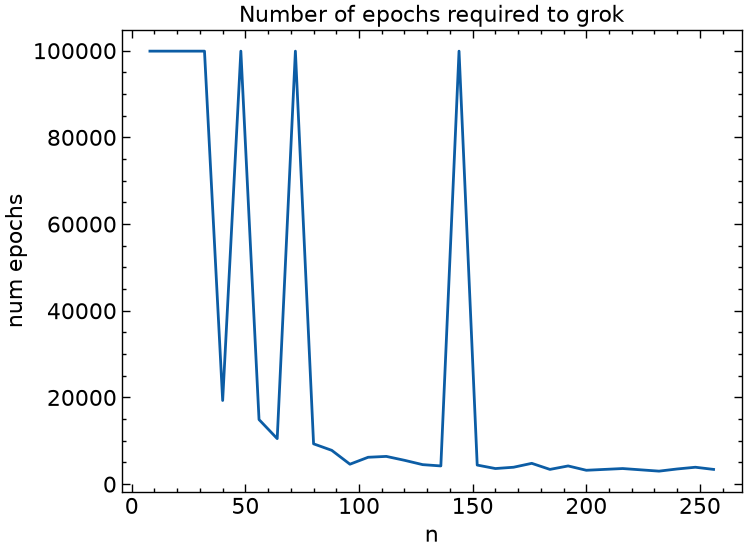

In [39]:
plt.plot(df['n'], df['num_epochs'])
plt.title('Number of epochs required to grok')
plt.xlabel("n")
plt.ylabel("num epochs")
plt.show()